In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style("darkgrid")

In [2]:
df = pd.read_csv('Geologic_DataSet.csv')
df.head()

,Porosity (%),Matrix Perm (nd),Acoustic impedance (kg/m2s*10^6),Brittleness Ratio,TOC (%),Vitrinite Reflectance (%),Aroot(K)
0,8.456,292,3.080,97.680,4.64,1.848,48.306469
1,8.666,353,3.542,55.404,3.56,1.504,41.300912
2,9.814,259,4.411,87.360,3.56,2.176,49.688356
3,12.369,675,2.893,47.772,4.32,1.504,59.132694
4,12.264,457,3.498,13.128,6.04,1.520,39.503121


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Porosity (%),200.0,10.493805,2.079824,4.585000,9.03875,10.549000,12.181750,16.485000
Matrix Perm (nd),200.0,433.075000,173.101415,113.000000,312.25000,403.500000,528.750000,987.000000
Acoustic impedance (kg/m2s*10^6),200.0,3.265735,0.623574,1.408000,2.80225,3.250500,3.679500,5.093000
Brittleness Ratio,200.0,57.794340,16.955346,13.128000,45.30600,59.412000,69.915000,101.196000
TOC (%),200.0,3.970700,1.907119,0.100000,2.47000,4.120000,5.400000,8.720000
Vitrinite Reflectance (%),200.0,1.571440,0.240662,0.744000,1.41600,1.568000,1.714000,2.296000
Aroot(K),200.0,50.000000,11.505310,24.437856,41.96103,49.692285,58.986667,77.270733


## Checking the distribution of each feature using histogram plots, this will give us better feeling the nature of our features

<Axes: xlabel='Aroot(K)', ylabel='Density'>

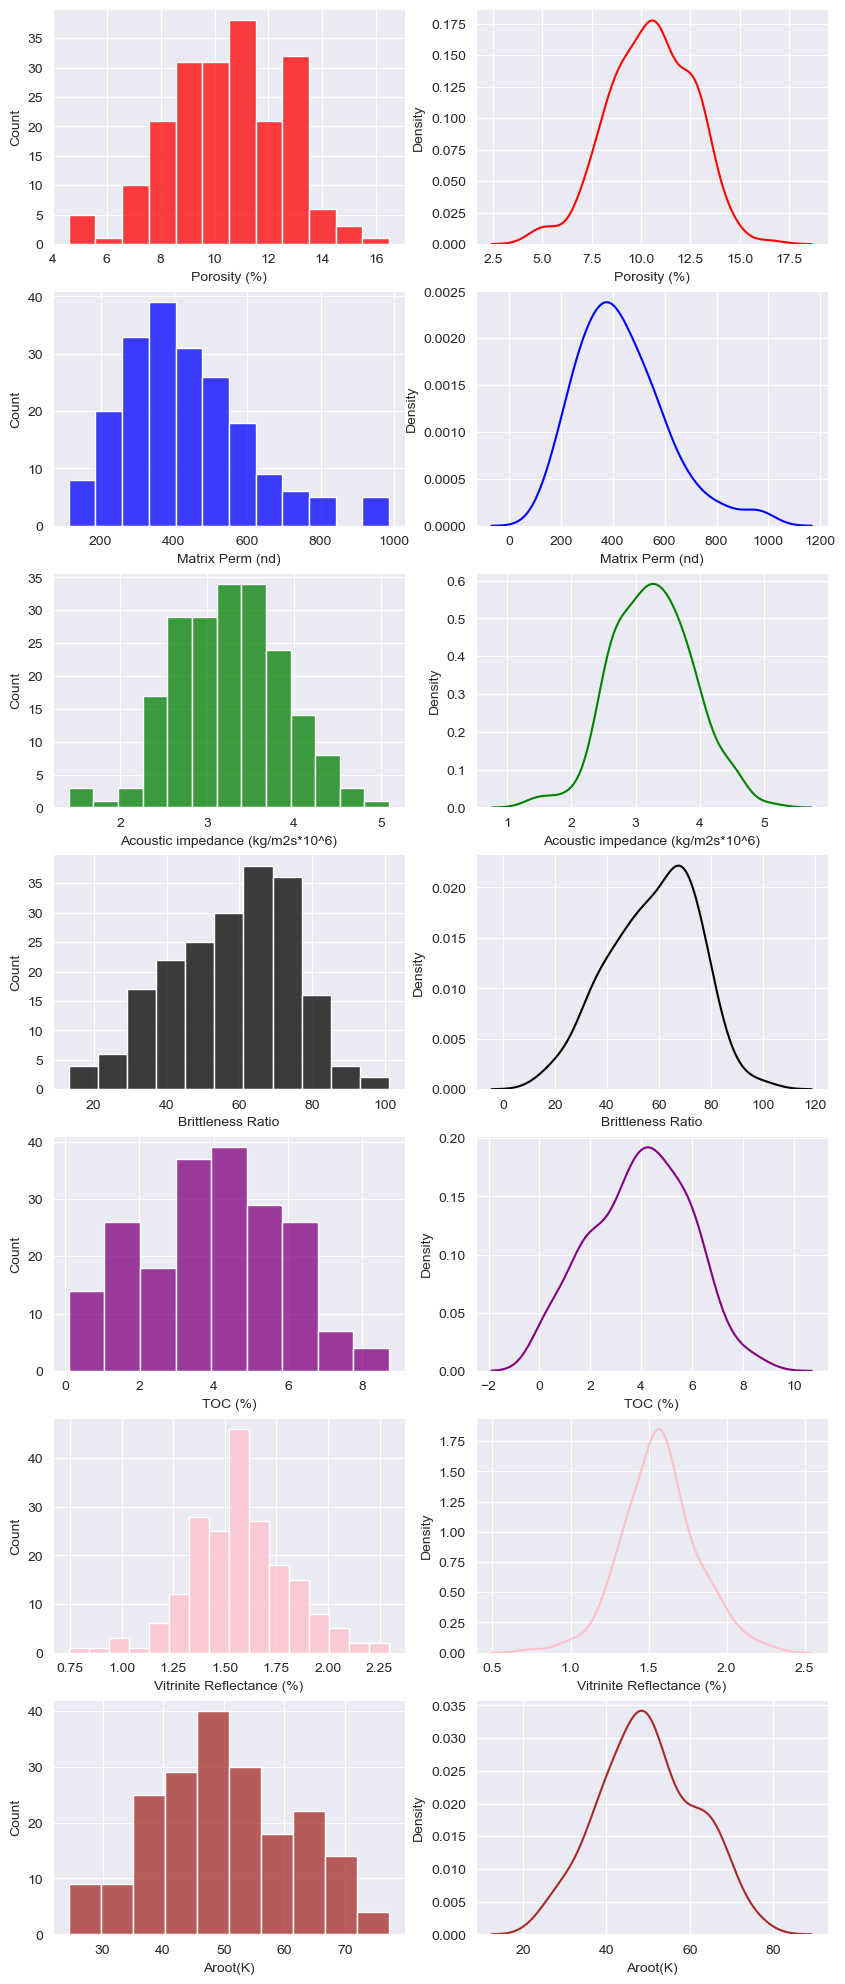

In [4]:
f, axes = plt.subplots(7, 2, figsize=(10,25))
sns.histplot(df[df.columns[0]], color = "red", ax = axes[0,0])
sns.kdeplot(df[df.columns[0]], color = "red", ax = axes[0,1])
sns.histplot(df[df.columns[1]], color = "blue", ax = axes[1,0])
sns.kdeplot(df[df.columns[1]], color = "blue", ax = axes[1,1])
sns.histplot(df[df.columns[2]], color = "green", ax = axes[2,0])
sns.kdeplot(df[df.columns[2]], color = "green", ax = axes[2,1])
sns.histplot(df[df.columns[3]], color = "black", ax = axes[3,0])
sns.kdeplot(df[df.columns[3]], color = "black", ax = axes[3,1])
sns.histplot(df[df.columns[4]], color = "purple", ax = axes[4,0])
sns.kdeplot(df[df.columns[4]], color = "purple", ax = axes[4,1])
sns.histplot(df[df.columns[5]], color = "pink", ax = axes[5,0])
sns.kdeplot(df[df.columns[5]], color = "pink", ax = axes[5,1])
sns.histplot(df[df.columns[6]], color = "brown", ax = axes[6,0])
sns.kdeplot(df[df.columns[6]], color = "brown", ax = axes[6,1])

## Box plots to check for outliers and median values

<Axes: xlabel='Aroot(K)'>

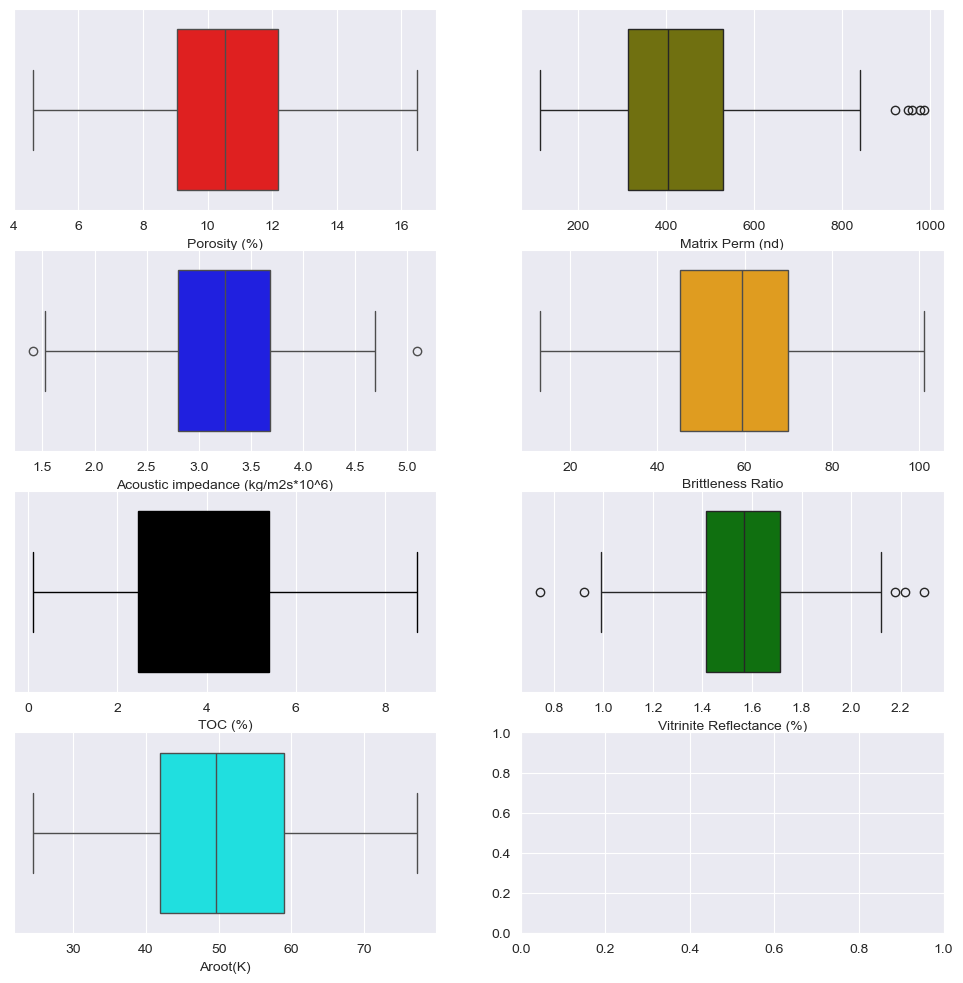

In [5]:
f, axes = plt.subplots(4, 2, figsize=(12, 12))
x=df['Porosity (%)']
sns.boxplot(x=x , color="red", ax=axes[0, 0])
#sns.boxplot(df['Porosity (%)'] , color="red", ax=axes[0, 0])
x=df['Matrix Perm (nd)']
sns.boxplot(x=x , color="olive", ax=axes[0, 1])
x=df['Acoustic impedance (kg/m2s*10^6)']
sns.boxplot(x=x , color="blue", ax=axes[1, 0])
x=df['Brittleness Ratio']
sns.boxplot(x=x , color="orange", ax=axes[1, 1])
x=df['TOC (%)'] 
sns.boxplot(x=x , color="black", ax=axes[2, 0])
x=df['Vitrinite Reflectance (%)']
sns.boxplot(x=x , color="green", ax=axes[2, 1])
x=df['Aroot(K)']
sns.boxplot(x=x , color="cyan", ax=axes[3, 0])

## Understanding the relationship between input features and output feature Aroot(k)

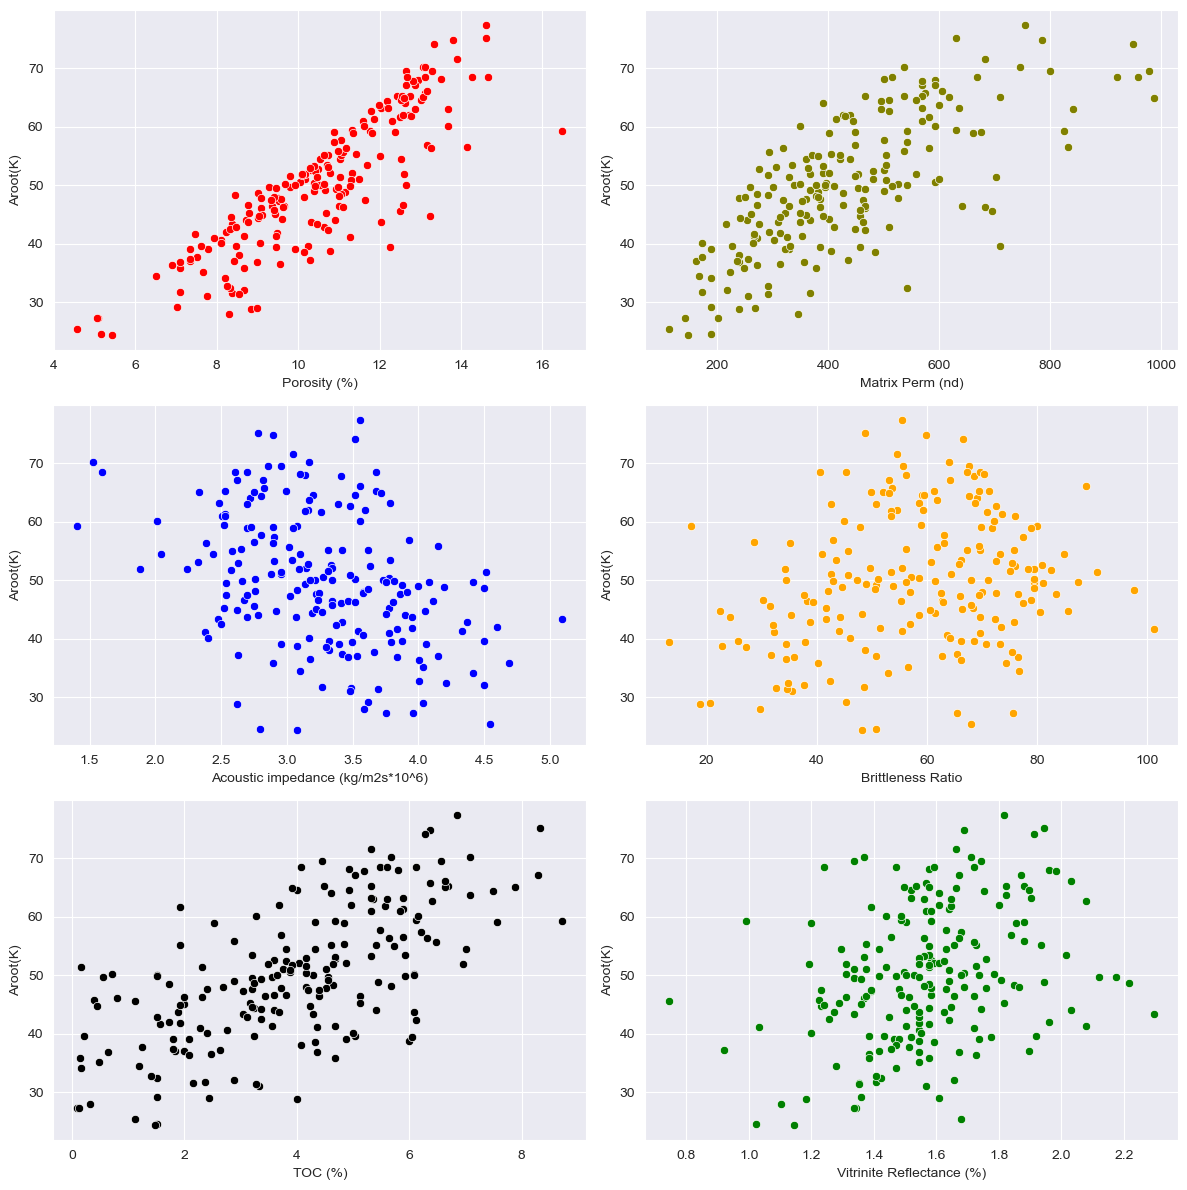

In [6]:
f, axes = plt.subplots(3, 2, figsize=(12, 12))
x=df['Porosity (%)']
y=df['Aroot(K)']
sns.scatterplot(x=x ,y=y, color="red", ax=axes[0, 0])
x=df['Matrix Perm (nd)']
sns.scatterplot(x=x ,y=y, color="olive", ax=axes[0, 1])
x=df['Acoustic impedance (kg/m2s*10^6)']
sns.scatterplot(x=x , y=y, color="blue", ax=axes[1, 0])
x=df['Brittleness Ratio']
sns.scatterplot(x=x , y=y, color="orange", ax=axes[1, 1])
x=df['TOC (%)']
sns.scatterplot(x=x, y=y, color="black", ax=axes[2, 0])
x=df['Vitrinite Reflectance (%)'] 
sns.scatterplot(x=x ,y=y, color="green", ax=axes[2, 1])

plt.tight_layout()

## Checking if there are linear correlations between features using Heatmap

#### *We can find that Matrix Perm and Porosity have Pearson correlation coefficient of 0.76 making them linerly related*
#### *We can find that TOC and Porosity have Pearson correlation coefficient of 0.71 making them linerly related*

<Axes: >

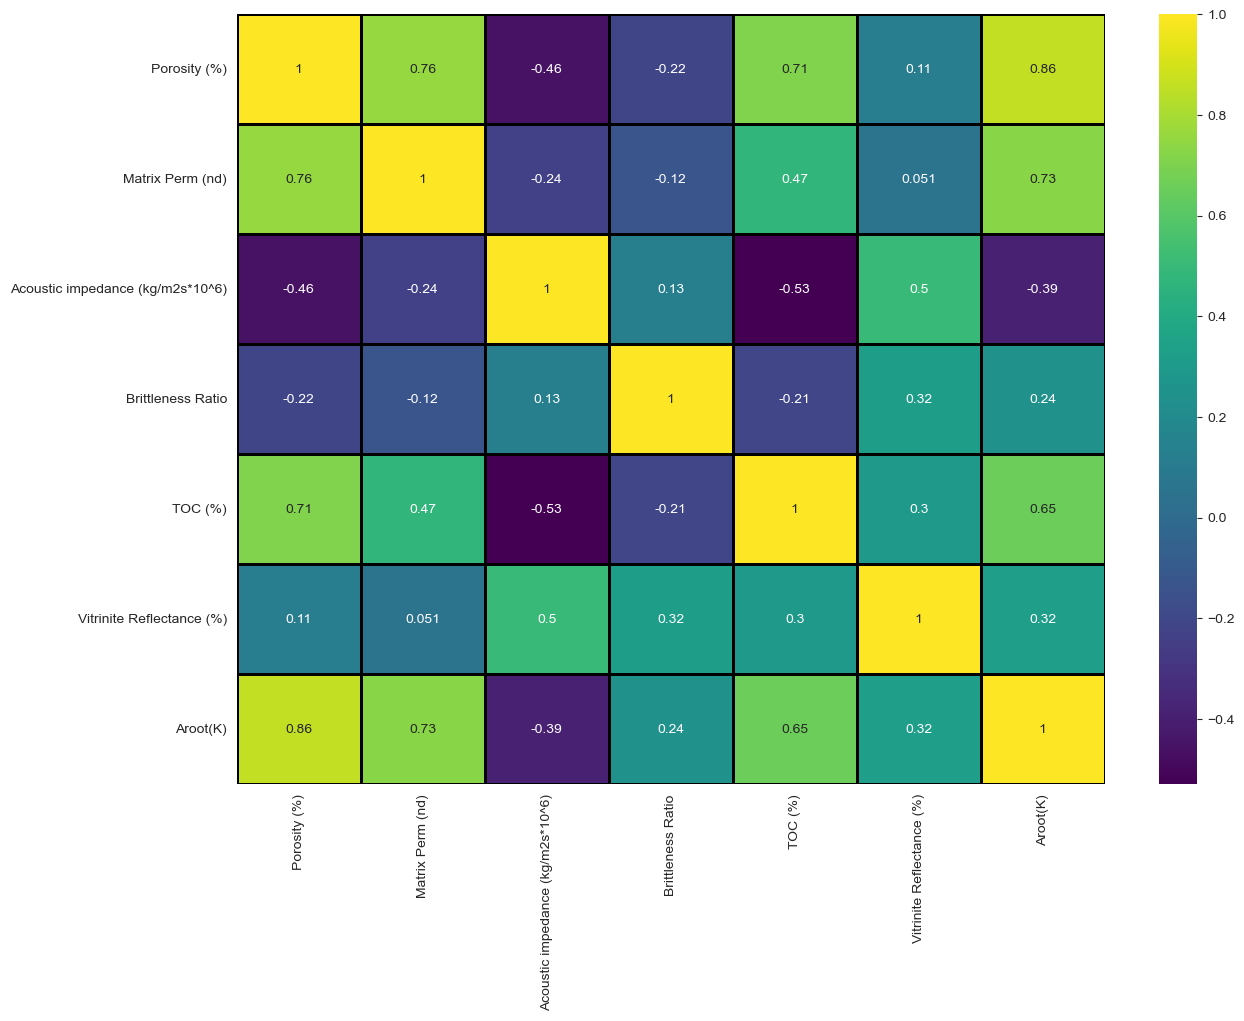

In [7]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), linewidths = 2, linecolor = 'black', cmap = 'viridis', annot = True)

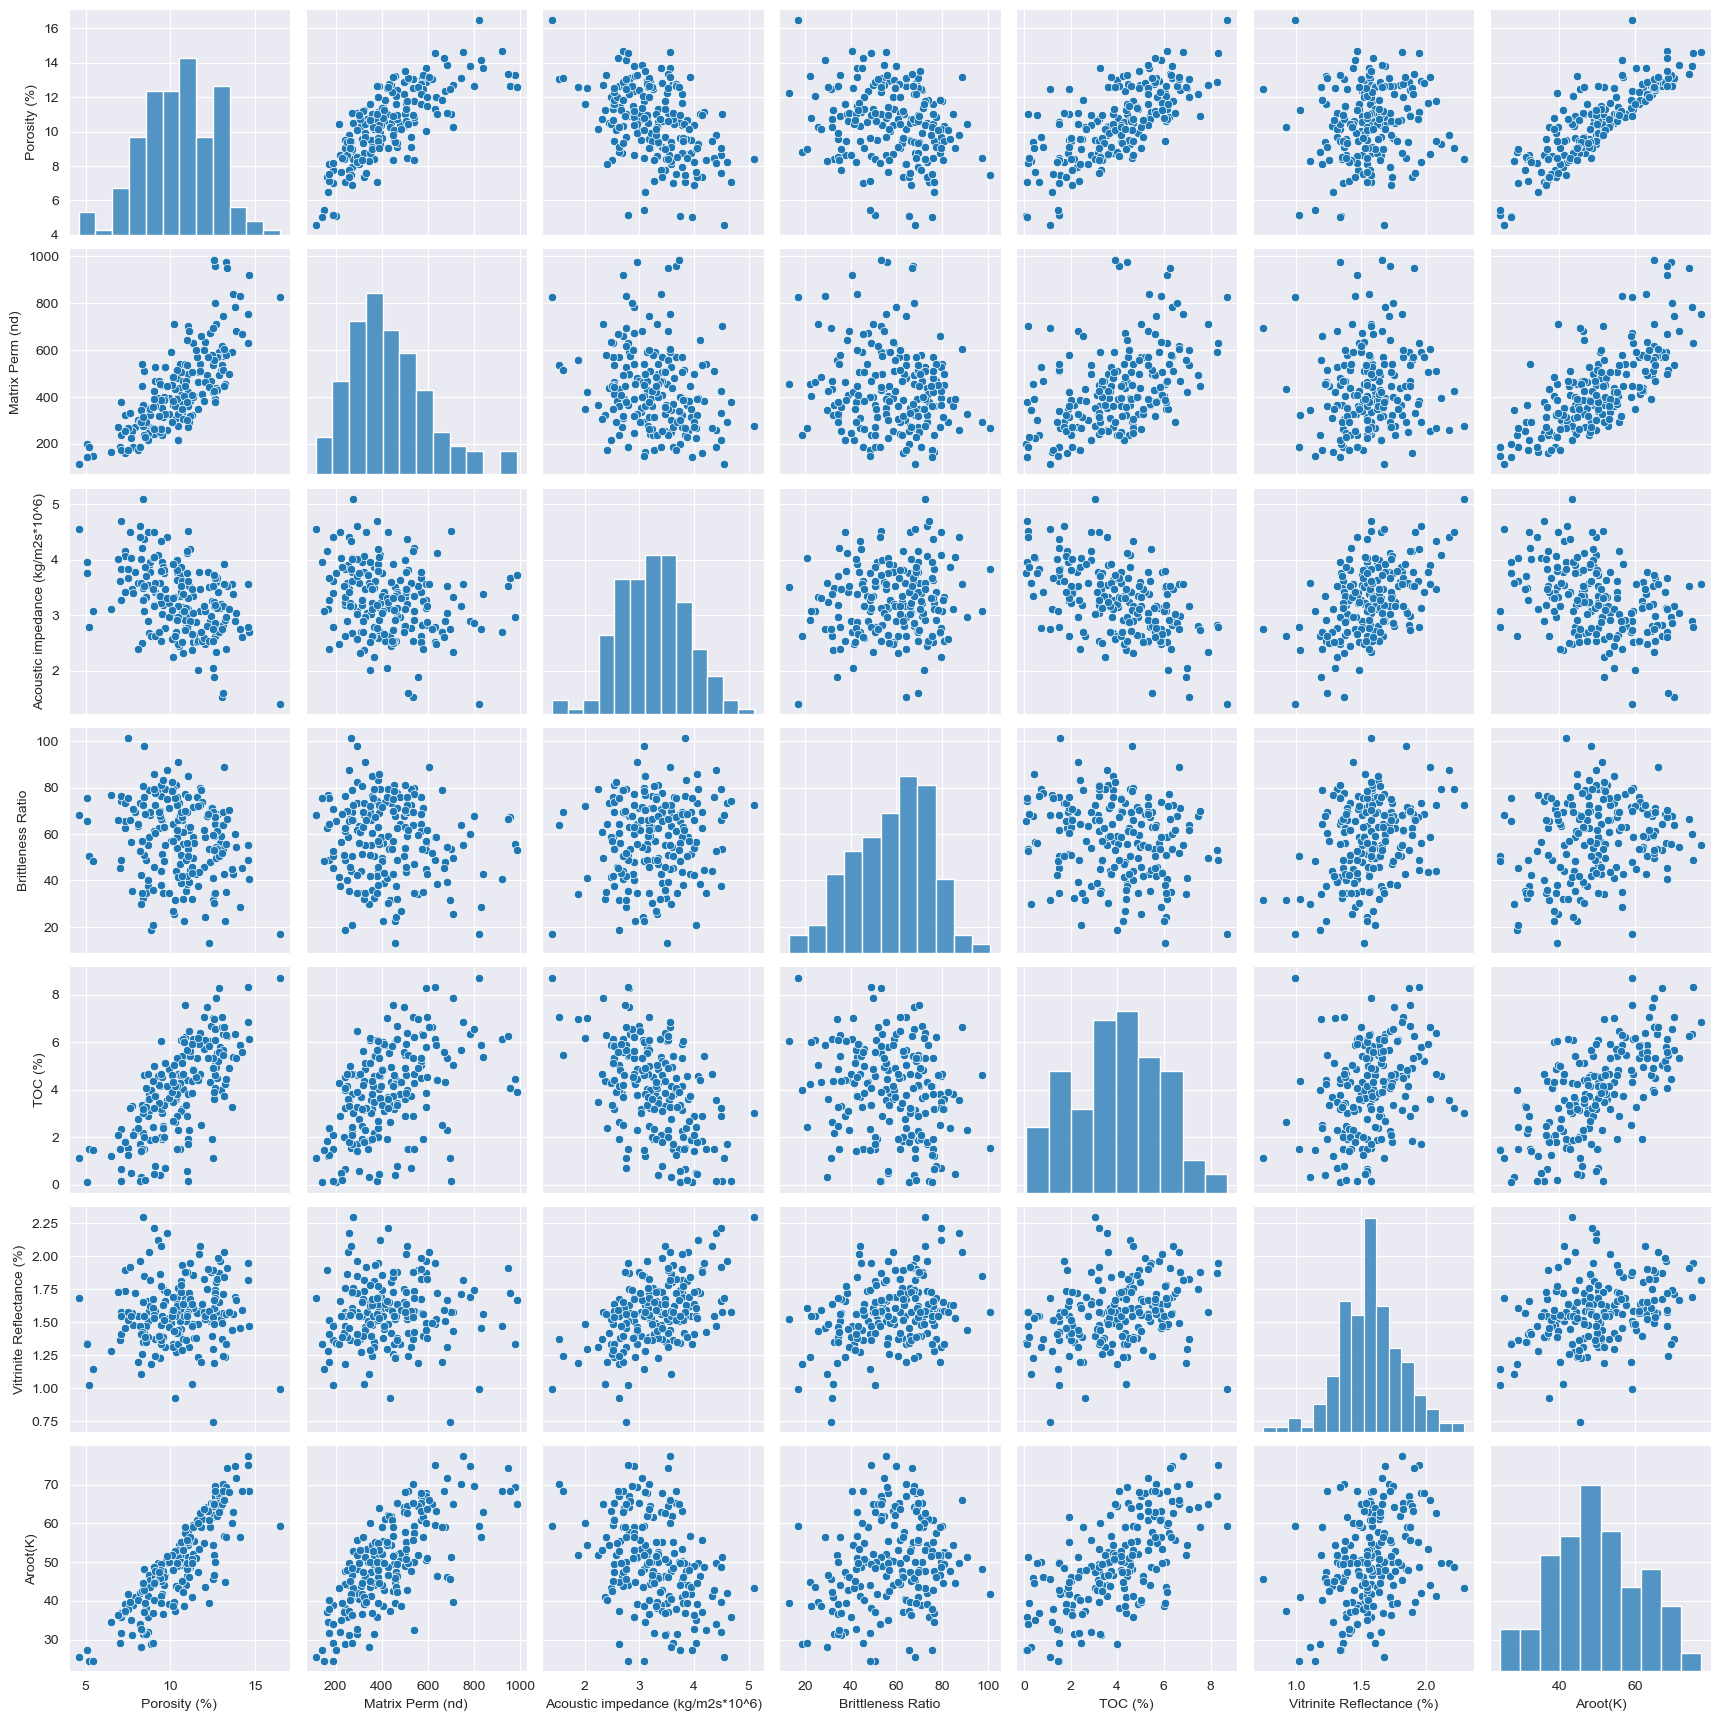

In [8]:
sns.pairplot(df)

In [9]:
Matrix_Perm, TOC = df.columns[1], df.columns[4]

df.drop([Matrix_Perm, TOC], axis = 1, inplace = True)

In [10]:
df.head()

,Porosity (%),Acoustic impedance (kg/m2s*10^6),Brittleness Ratio,Vitrinite Reflectance (%),Aroot(K)
0,8.456,3.080,97.680,1.848,48.306469
1,8.666,3.542,55.404,1.504,41.300912
2,9.814,4.411,87.360,2.176,49.688356
3,12.369,2.893,47.772,1.504,59.132694
4,12.264,3.498,13.128,1.520,39.503121


# Feature Engineering

* We will normalize the data frame

In [11]:
from sklearn import preprocessing

In [12]:
scaler = preprocessing.MinMaxScaler(feature_range=(0,1))
scaler.fit(df)
df_scaled = scaler.transform(df)
df_scaled = pd.DataFrame(df_scaled, columns=[df.columns[0], df.columns[1], df.columns[2], df.columns[3], df.columns[4]])

In [13]:
df_scaled

,Porosity (%),Acoustic impedance (kg/m2s*10^6),Brittleness Ratio,Vitrinite Reflectance (%),Aroot(K)
0,0.325294,0.453731,0.960076,0.711340,0.451776
1,0.342941,0.579104,0.480038,0.489691,0.319177
2,0.439412,0.814925,0.842894,0.922680,0.477932
3,0.654118,0.402985,0.393378,0.489691,0.656690
4,0.645294,0.567164,0.000000,0.500000,0.285149
...,...,...,...,...,...
195,0.317647,0.504478,0.766317,0.582474,0.382052
196,0.672941,0.626866,0.454830,0.592784,0.767007
197,0.327647,0.668657,0.628560,0.412371,0.285905
198,0.529412,0.358209,0.644638,0.731959,0.654256


In [14]:
y_scaled = df_scaled['Aroot(K)']
x_scaled = df_scaled.drop(['Aroot(K)'], axis = 1)

In [15]:
from sklearn.model_selection import train_test_split
seed = 1000
np.random.seed(seed)
X_train, X_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size = 0.3)
X_train

,Porosity (%),Acoustic impedance (kg/m2s*10^6),Brittleness Ratio,Vitrinite Reflectance (%)
44,0.695294,0.382090,0.453468,0.726804
101,0.401176,0.525373,0.562611,0.407216
25,0.042353,0.635821,0.594359,0.386598
3,0.654118,0.402985,0.393378,0.489691
68,0.487647,0.641791,0.515874,0.608247
...,...,...,...,...
94,0.541176,0.459701,0.814007,0.572165
192,0.812941,0.325373,0.365445,0.546392
71,0.448235,0.489552,0.658945,0.505155
87,0.490000,0.602985,0.713585,0.567010


In [16]:
df.columns

Index(['Porosity (%)', 'Acoustic impedance (kg/m2s*10^6)', 'Brittleness Ratio',
       'Vitrinite Reflectance (%)', 'Aroot(K)'],
      dtype='object')

In [17]:
from sklearn.linear_model import LinearRegression
np.random.seed(seed)
lm = LinearRegression()
lm.fit(X_train, y_train)

LinearRegression()

In [18]:
print(lm.intercept_)

-0.2956531626291043


In [19]:
coeff_df = pd.DataFrame(lm.coef_, x_scaled.columns, columns = ['Coefficient'])
coeff_df

,Coefficient
Porosity (%),1.069765
Acoustic impedance (kg/m2s*10^6),-0.178141
Brittleness Ratio,0.426330
Vitrinite Reflectance (%),0.231669


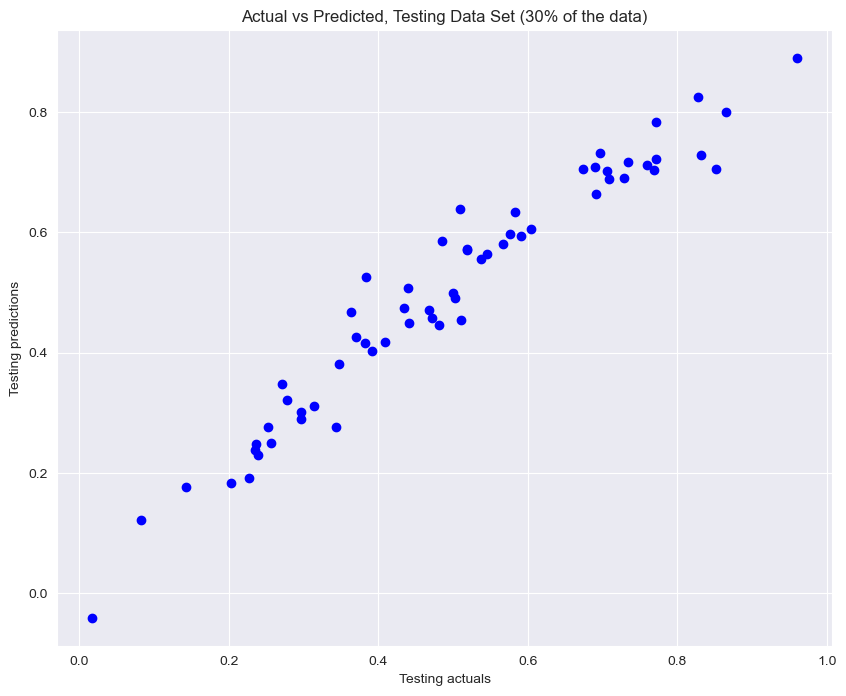

In [20]:
f, ax = plt.subplots(figsize = (10, 8))
y_pred = lm.predict(X_test)
ax.scatter(y_test, y_pred, c='b')
ax.set(xlabel = 'Testing actuals', ylabel = 'Testing predictions', title = 'Actual vs Predicted, Testing Data Set (30% of the data)')
plt.show()

In [21]:
from sklearn import *
test_set_r2 = metrics.r2_score(y_test, y_pred)
print('Testing r^2:', round(test_set_r2,2))

Testing r^2: 0.94


In [22]:
print('MAE: ', round(metrics.mean_absolute_error(y_test, y_pred),5))
print('MSE: ', round(metrics.mean_squared_error(y_test, y_pred),5))
print('RMSE: ', round(np.sqrt(metrics.mean_squared_error(y_test, y_pred)),5))

MAE:  0.03793
MSE:  0.00266
RMSE:  0.05159


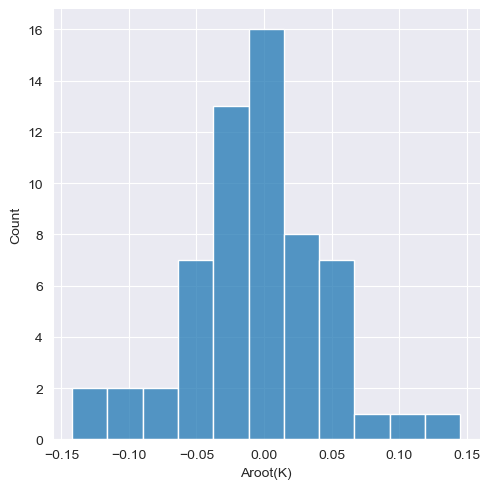

In [23]:
sns.displot((y_test-y_pred))

## Hypothesis Testing
* H0 : Brittleness Ratio is highly correlated to the Aroot(K)
* H1 : Brittleness Ratio are not correlated to the Aroot(K)

In [24]:
df['Aroot(K)'].corr(df['Brittleness Ratio'])

0.23715533470622957

In [25]:
from scipy import stats

In [26]:
df.columns

Index(['Porosity (%)', 'Acoustic impedance (kg/m2s*10^6)', 'Brittleness Ratio',
       'Vitrinite Reflectance (%)', 'Aroot(K)'],
      dtype='object')

In [27]:
# To find the correlation value and p-value

r, p = stats.pearsonr(df['Aroot(K)'], df['Brittleness Ratio'])

In [28]:
print(f"The Correlation value is {round(r, 4)}")
print(f"The P-Value is : {round(p, 4)}")

The Correlation value is 0.2372
The P-Value is : 0.0007


In [29]:
# Defining the Signifigance level and evaluation the hypothesis

signifigance_level = 0.05
if p < signifigance_level:
    print("Reject null hypothesis: Brittleness Ratio are not highly correlated to the Aroot(K)")
else:
    print("Accept null hypothesis: Brittleness Ratio are highly correlated to the Aroot(K)")

Reject null hypothesis: Brittleness Ratio are not highly correlated to the Aroot(K)


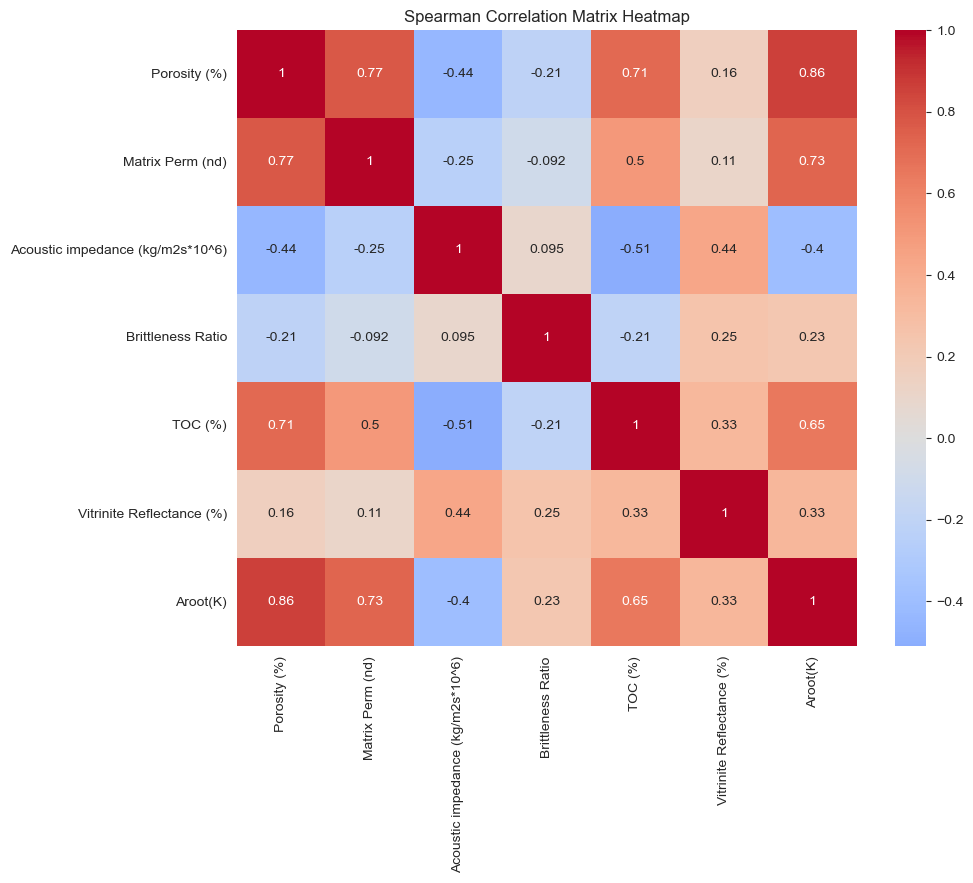

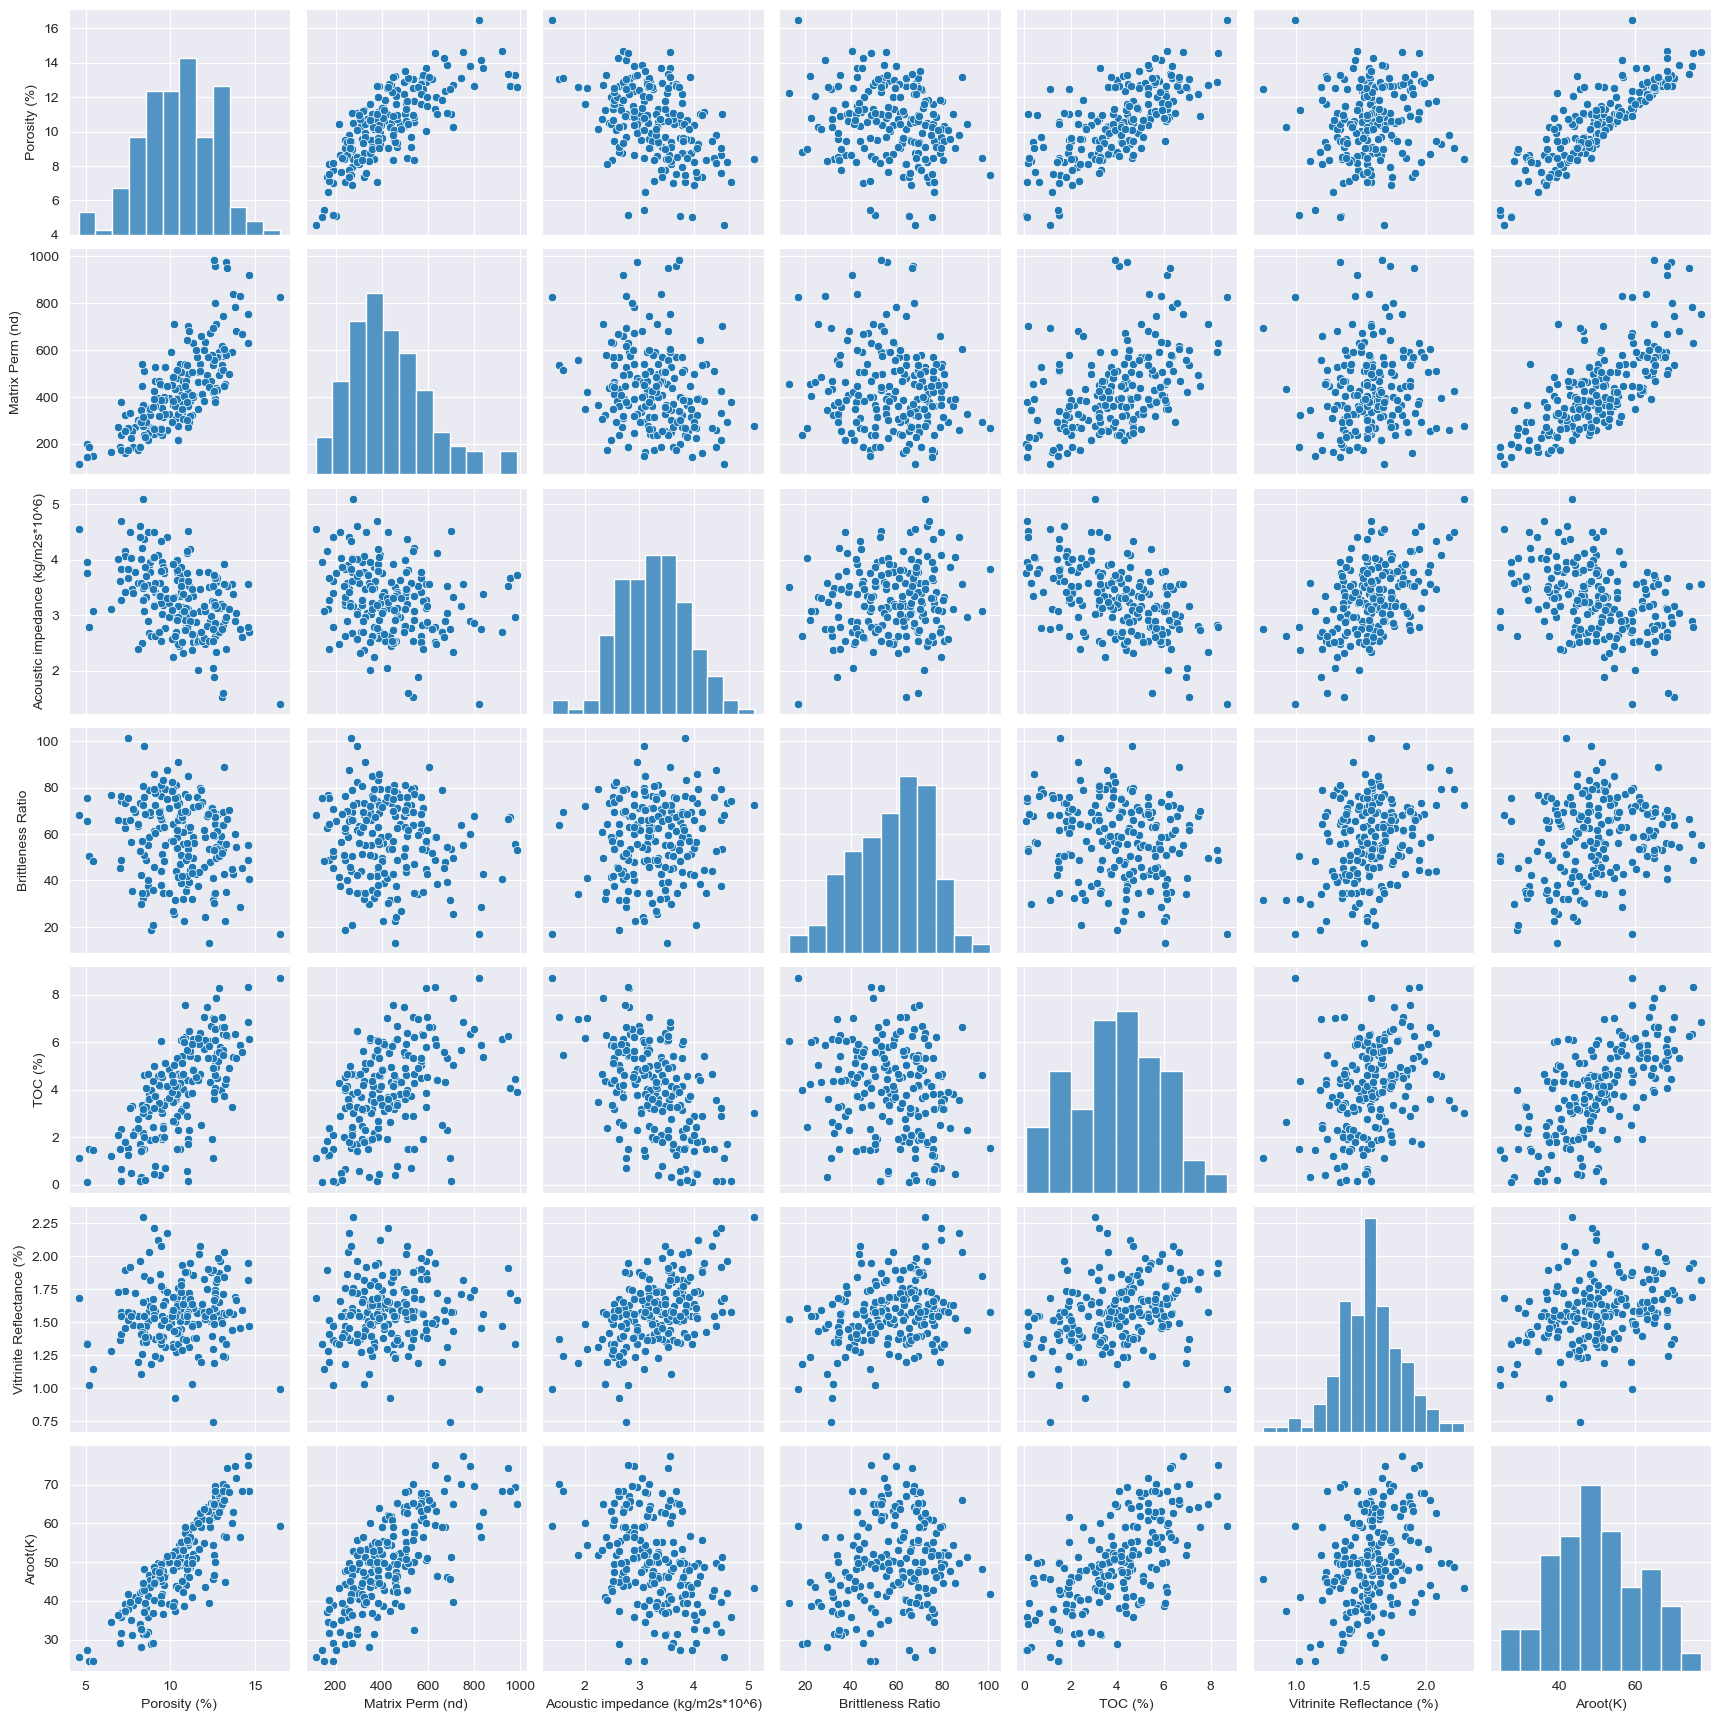

In [30]:
# Python Pseudocode for EDA
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('Geologic_DataSet.csv')

# Generate correlation matrix heatmap
corr_matrix = df.corr(method='spearman') # Use spearman for non-linear relationships
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

# Create a pairplot to visualize relationships
sns.pairplot(df)
plt.show()